# Ecuación de Poisson comóvil en 2D — LFIS428, Grupo 3

Este cuaderno reúne todo el trabajo de la Etapa 1:

1. **Física**: la ecuación de Poisson en coordenadas comóviles y por qué es el "motor de gravedad" de una simulación cosmológica.
2. **Código C** (`poisson_comovil_cpu.c`): la versión periódica del código de referencia, compilada y validada aquí mismo.
3. **Validación**: error $O(h^2)$, número de iteraciones vs. teoría, comparación con FFT y espectros de potencia.
4. **Simulación particle-mesh 2D**: el solver de Poisson usado para formar la red cósmica, y la comparación con la teoría lineal.

Funciona igual en **Google Colab** y en **Jupyter de VS Code** (necesita `gcc`, `numpy` y `matplotlib`).

In [1]:
import os, subprocess, shutil, time
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

print("gcc:", shutil.which("gcc"))
os.makedirs("poisson2d", exist_ok=True)
os.chdir("poisson2d")
print("Directorio de trabajo:", os.getcwd())

gcc: /usr/bin/gcc
Directorio de trabajo: /home/claude/nb/poisson2d


## 1. La física en una página

**Newton en coordenadas comóviles.** Con $\mathbf r = a(t)\,\mathbf x$ y $\Phi = \Phi_0 + \phi$, el potencial del fondo homogéneo genera exactamente la expansión ($\ddot a/a = -\tfrac{4\pi G}{3}\bar\rho$) y lo que queda es

$$
\ddot{\mathbf x} + 2H\dot{\mathbf x} = -\frac{1}{a^2}\nabla_x\phi,
\qquad
\nabla_x^2\phi = 4\pi G\,a^2\bar\rho\,\delta = \frac32\,\frac{\Omega_m H_0^2}{a}\,\delta .
$$

**Unidades de código.** Con $\tilde{\mathbf x} = \mathbf x/L$ y $\tilde\phi = \phi/(H_0L)^2$:

$$
\boxed{\nabla^2\tilde\phi = \frac32\,\frac{\Omega_m}{a}\,\delta}
$$

Es exactamente el $\nabla^2 u = f$ del código del profesor, con $f = \tfrac32(\Omega_m/a)\,(\delta - \langle\delta\rangle)$ en una **caja periódica**.

**Crecimiento lineal.** Linealizando continuidad y Euler (momentos de la ecuación de Vlasov con $\sigma_{ij}=0$):

$$
\ddot\delta + 2H\dot\delta = 4\pi G\bar\rho\,\delta
\;\;\xrightarrow{\text{EdS}}\;\;
\delta\propto a,\qquad \phi \propto a^2\bar\rho\,\delta \propto a^2\,a^{-3}\,a = \text{cte.}
$$

La densidad crece pero el potencial se congela: lo comprobamos en la sección 5.

## 2. El código C periódico

Cambios respecto a `poisson_cpu.c` del profesor:

| Cambio | Por qué |
|---|---|
| $h = 1/N$, vecinos con módulo (`mas`, `menos`, `vecinos`) | La caja cosmológica no tiene borde: se repite. |
| Se actualizan **todos** los puntos | No hay puntos de borde fijos. |
| `f = 1.5*Om/a*(delta - <delta>)` | Condición de compatibilidad $\sum f = 0$: sin ella no hay solución. |
| `restar_promedio(u)` en cada chequeo | $\phi$ está definido salvo una constante (modo cero). |
| $\omega = 2/\big(1+\sin\pi h\,\sqrt{1+\cos^2\pi h}\big)$ | El modo de error más lento es $(1,0)$, con $\rho_J = \cos^2(\pi h)$. |
| `modo 0`: test de un modo; `modo 1`: lee `delta.bin` | Validación con solución exacta, y campo cosmológico realista. |

La estructura es la misma: `main` → fuente → bucle (100 iteraciones de Jacobi o rojo-negro) → `norma_residuo` → salida.
Cada función es un doble bucle sobre la malla, que en la Etapa 2 se convierte en un kernel con un thread por punto.

In [2]:
%%writefile poisson_comovil_cpu.c
/*
 * Proyecto: ecuación de Poisson comóvil en 2D (versión CPU de referencia)
 * Modificación de poisson_cpu.c para el potencial gravitatorio peculiar.
 *
 * Ecuación física (coordenadas comóviles x, potencial peculiar phi):
 *     lap_x phi = (3/2) Omega_m H0^2 delta / a
 *
 * Unidades de código: x~ = x / L  (caja periódica [0,1) x [0,1)),
 *                     phi~ = phi / (H0 L)^2
 *     =>  lap phi~ = (3/2) (Omega_m / a) delta        (sin constantes)
 *
 * Cambios respecto al código del profesor:
 *   1. Bordes periódicos: N puntos por lado, h = 1/N, índices con módulo.
 *      Se actualizan TODOS los puntos (no hay borde fijo).
 *   2. Fuente f = (3/2)(Om/a)(delta - <delta>): se resta el promedio para
 *      cumplir la condición de compatibilidad  sum(f) = 0.
 *   3. El potencial queda definido salvo una constante: se fija <phi> = 0.
 *   4. SOR con w_opt periódico: el modo de error más lento es (1,0),
 *      k = (2 pi, 0), con factor de Jacobi rho_J = [1 + cos(2 pi h)]/2
 *      = cos^2(pi h). Entonces w = 2 / (1 + sqrt(1 - rho_J^2))
 *      = 2 / (1 + sin(pi h) sqrt(1 + cos^2(pi h))).
 *   5. Dos fuentes posibles:
 *        modo 0: test con un solo modo, delta = A cos(2 pi m x) cos(2 pi n y)
 *                (solución discreta y continua exactas conocidas)
 *        modo 1: delta leído de 'delta.bin' (p.ej. campo gaussiano
 *                generado con generar_delta.py)
 *
 * Compilar:  gcc -O2 poisson_comovil_cpu.c -lm -o poisson_comovil_cpu.x
 * Ejecutar:  ./poisson_comovil_cpu.x [N] [metodo] [tol] [modo] [Om] [a]
 *            N debe ser par (rojo-negro periódico).
 * Salida:    salida_cpu.bin con dos campos: phi y delta (formato del profesor)
 */

#include <math.h>
#include <stdio.h>
#include <stdlib.h>
#include <sys/time.h>

#define PI 3.14159265358979323846

typedef double real;

double segundos(void) {
  struct timeval tp;
  gettimeofday(&tp, NULL);
  return ((double)tp.tv_sec + (double)tp.tv_usec * 1.e-6);
}

void escribir_salida(const char *nombre, int nx, int ny, int ncampos,
                     real **campos) {
  FILE *f = fopen(nombre, "wb");
  int cabecera[4] = {nx, ny, ncampos, (int)sizeof(real)};
  fwrite(cabecera, sizeof(int), 4, f);
  for (int c = 0; c < ncampos; c++)
    fwrite(campos[c], sizeof(real), (size_t)nx * ny, f);
  fclose(f);
}

// Lee delta desde un archivo con el mismo formato (cabecera + 1 campo)
int leer_delta(const char *nombre, real *delta, int N) {
  FILE *f = fopen(nombre, "rb");
  if (!f) return 1;
  int cab[4];
  if (fread(cab, sizeof(int), 4, f) != 4 || cab[0] != N || cab[1] != N ||
      cab[3] != (int)sizeof(real)) {
    fclose(f);
    return 2;
  }
  size_t n = fread(delta, sizeof(real), (size_t)N * N, f);
  fclose(f);
  return (n == (size_t)N * N) ? 0 : 3;
}

// Vecinos periódicos
static inline int mas(int i, int N) { return (i + 1 == N) ? 0 : i + 1; }
static inline int menos(int i, int N) { return (i == 0) ? N - 1 : i - 1; }

// Suma de los 4 vecinos del punto (i,j) con bordes periódicos
static inline real vecinos(const real *u, int i, int j, int N) {
  return u[j * N + mas(i, N)] + u[j * N + menos(i, N)] +
         u[mas(j, N) * N + i] + u[menos(j, N) * N + i];
}

void iteracion_jacobi(const real *u, real *u_new, const real *f, int N,
                      real h2) {
  for (int j = 0; j < N; j++)
    for (int i = 0; i < N; i++)
      u_new[j * N + i] = 0.25 * (vecinos(u, i, j, N) - h2 * f[j * N + i]);
}

// Media iteración rojo-negro sobre los puntos con (i + j) % 2 == color
void media_iteracion_rb(real *u, const real *f, int N, real h2, real w,
                        int color) {
  for (int j = 0; j < N; j++)
    for (int i = (j + color) % 2; i < N; i += 2) {
      int idx = j * N + i;
      real gs = 0.25 * (vecinos(u, i, j, N) - h2 * f[idx]);
      u[idx] += w * (gs - u[idx]);
    }
}

real norma_residuo(const real *u, const real *f, int N, real h2) {
  real suma = 0.0;
  for (int j = 0; j < N; j++)
    for (int i = 0; i < N; i++) {
      real lap = (vecinos(u, i, j, N) - 4.0 * u[j * N + i]) / h2;
      real r = f[j * N + i] - lap;
      suma += r * r;
    }
  return sqrt(suma);
}

real norma(const real *f, int N) {
  real suma = 0.0;
  for (int k = 0; k < N * N; k++) suma += f[k] * f[k];
  return sqrt(suma);
}

real promedio(const real *f, int N) {
  real suma = 0.0;
  for (int k = 0; k < N * N; k++) suma += f[k];
  return suma / ((real)N * N);
}

// Fija el modo cero: <u> = 0
void restar_promedio(real *u, int N) {
  real m = promedio(u, N);
  for (int k = 0; k < N * N; k++) u[k] -= m;
}

int main(int argc, char **argv) {
  int N = (argc > 1) ? atoi(argv[1]) : 256;
  int metodo = (argc > 2) ? atoi(argv[2]) : 2;
  real tol = (argc > 3) ? atof(argv[3]) : 1e-8;
  int modo = (argc > 4) ? atoi(argv[4]) : 0;
  real Om = (argc > 5) ? atof(argv[5]) : 0.3;
  real a = (argc > 6) ? atof(argv[6]) : 1.0;

  const char *nombres[3] = {"Jacobi", "Gauss-Seidel rojo-negro",
                            "SOR rojo-negro"};
  if (metodo < 0 || metodo > 2 || N % 2 != 0) {
    fprintf(stderr, "metodo debe ser 0, 1 o 2 y N debe ser par\n");
    return 1;
  }

  real h = 1.0 / N;  // periódico: x_i = i h, i = 0..N-1
  real h2 = h * h;
  // rho_J = cos^2(pi h) (modo (1,0)) => w = 2/(1+sqrt(1-rho_J^2))
  real w = (metodo == 2) ? 2.0 / (1.0 + sin(PI * h) * sqrt(1.0 + pow(cos(PI * h), 2))) : 1.0;
  int chequeo = 100;
  int max_iter = 10000000;

  real *u = (real *)calloc((size_t)N * N, sizeof(real));
  real *u_new = (real *)calloc((size_t)N * N, sizeof(real));
  real *f = (real *)malloc((size_t)N * N * sizeof(real));
  real *delta = (real *)malloc((size_t)N * N * sizeof(real));

  // Parámetros del test de un modo
  const int m = 1, n = 2;
  const real A = 1.0;

  if (modo == 0) {
    for (int j = 0; j < N; j++)
      for (int i = 0; i < N; i++)
        delta[j * N + i] = A * cos(2 * PI * m * i * h) * cos(2 * PI * n * j * h);
  } else {
    int e = leer_delta("delta.bin", delta, N);
    if (e) {
      fprintf(stderr, "error %d leyendo delta.bin (¿mismo N?)\n", e);
      return 1;
    }
  }

  // Fuente comóvil en unidades de código, con promedio restado
  real dmed = promedio(delta, N);
  real pref = 1.5 * Om / a;
  for (int k = 0; k < N * N; k++) f[k] = pref * (delta[k] - dmed);
  real norma_f = norma(f, N);

  printf("Poisson comóvil 2D periódico: N = %d, método = %s", N,
         nombres[metodo]);
  if (metodo == 2) printf(" (w = %.6f)", w);
  printf(", tol = %.1e, Om = %.3f, a = %.3f, <delta> = %.2e\n", tol, Om, a,
         dmed);

  double t0 = segundos();
  int iter = 0;
  real res = 1.0;
  while (iter < max_iter) {
    for (int k = 0; k < chequeo; k++) {
      if (metodo == 0) {
        iteracion_jacobi(u, u_new, f, N, h2);
        real *tmp = u;
        u = u_new;
        u_new = tmp;
      } else {
        media_iteracion_rb(u, f, N, h2, w, 0);
        media_iteracion_rb(u, f, N, h2, w, 1);
      }
    }
    iter += chequeo;
    restar_promedio(u, N);  // evita que el modo cero derive por redondeo
    res = norma_residuo(u, f, N, h2) / norma_f;
    if (res < tol) break;
  }
  double t_total = segundos() - t0;

  printf("Iteraciones: %d, residuo relativo = %.3e\n", iter, res);
  printf("Tiempo de cómputo: %.3f s (%.3f ms por iteración)\n", t_total,
         1e3 * t_total / iter);

  if (modo == 0) {
    // Autovalores del laplaciano discreto y continuo para cos(2pi m x)cos(2pi n y)
    real lam_d = -4.0 / h2 * (pow(sin(PI * m * h), 2) + pow(sin(PI * n * h), 2));
    real lam_c = -4.0 * PI * PI * (m * m + n * n);
    real err_d = 0.0, err_c = 0.0, umax = 0.0;
    for (int j = 0; j < N; j++)
      for (int i = 0; i < N; i++) {
        real modo_ij = cos(2 * PI * m * i * h) * cos(2 * PI * n * j * h);
        real ud = pref * A * modo_ij / lam_d;
        real uc = pref * A * modo_ij / lam_c;
        real v = u[j * N + i];
        if (fabs(v - ud) > err_d) err_d = fabs(v - ud);
        if (fabs(v - uc) > err_c) err_c = fabs(v - uc);
        if (fabs(uc) > umax) umax = fabs(uc);
      }
    printf("Error vs. solución discreta exacta (solver):        %.3e\n",
           err_d / umax);
    printf("Error vs. solución continua (discretización, ~h^2): %.3e (h^2 = %.3e)\n",
           err_c / umax, h2);
  }

  real *campos[2] = {u, delta};
  escribir_salida("salida_cpu.bin", N, N, 2, campos);

  free(u);
  free(u_new);
  free(f);
  free(delta);
  return 0;
}


Writing poisson_comovil_cpu.c


In [3]:
r = subprocess.run(["gcc", "-O2", "poisson_comovil_cpu.c", "-lm", "-o", "poisson_comovil_cpu.x"],
                   capture_output=True, text=True)
print(r.stderr or "Compilado OK")

def correr(N, metodo=2, tol=1e-10, modo=0, Om=0.3, a=1.0):
    # Ejecuta el código C y devuelve su salida de texto
    args = ["./poisson_comovil_cpu.x", str(N), str(metodo), str(tol), str(modo), str(Om), str(a)]
    return subprocess.run(args, capture_output=True, text=True).stdout

print(correr(128))

Compilado OK
Poisson comóvil 2D periódico: N = 128, método = SOR rojo-negro (w = 1.932925), tol = 1.0e-10, Om = 0.300, a = 1.000, <delta> = -2.15e-18
Iteraciones: 400, residuo relativo = 2.115e-11
Tiempo de cómputo: 0.011 s (0.027 ms por iteración)
Error vs. solución discreta exacta (solver):        1.320e-13
Error vs. solución continua (discretización, ~h^2): 6.830e-04 (h^2 = 6.104e-05)



## 3. Validación con un modo exacto

Con $\delta = \cos(2\pi x)\cos(4\pi y)$, el laplaciano discreto actúa sobre cada coseno como

$$
\frac{\cos k(x+h) + \cos k(x-h) - 2\cos kx}{h^2} = -\frac{4}{h^2}\sin^2\!\frac{kh}{2}\,\cos kx ,
$$

así que hay dos soluciones de referencia:
- la **discreta** (mide el error del *solver*, debe ser ~tolerancia),
- la **continua**, con autovalor $-4\pi^2(m^2+n^2)$ (mide el error de *discretización*, debe ser $O(h^2)$).

 N    error solver   error discretización   cociente
  32   2.74e-13       1.099e-02           nan
  64   1.70e-13       2.735e-03           4.02
 128   1.32e-13       6.830e-04           4.00
 256   1.02e-13       1.707e-04           4.00
 512   1.43e-13       4.267e-05           4.00


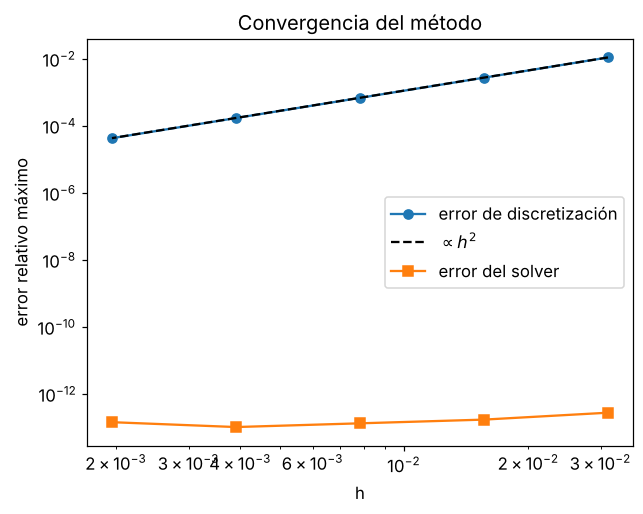

In [4]:
import re
Ns = [32, 64, 128, 256, 512]
err_solver, err_disc = [], []
for N in Ns:
    out = correr(N, metodo=2, tol=1e-10, modo=0)
    err_solver.append(float(re.search(r"discreta exacta \(solver\):\s+([\d.e+-]+)", out).group(1)))
    err_disc.append(float(re.search(r"~h\^2\):\s+([\d.e+-]+)", out).group(1)))

h = 1/np.array(Ns)
print(" N    error solver   error discretización   cociente")
for i, N in enumerate(Ns):
    q = err_disc[i-1]/err_disc[i] if i else float("nan")
    print(f"{N:4d}   {err_solver[i]:.2e}       {err_disc[i]:.3e}           {q:.2f}")

plt.loglog(h, err_disc, "o-", label="error de discretización")
plt.loglog(h, err_disc[0]*(h/h[0])**2, "k--", label=r"$\propto h^2$")
plt.loglog(h, err_solver, "s-", label="error del solver")
plt.xlabel("h"); plt.ylabel("error relativo máximo"); plt.legend(); plt.title("Convergencia del método")
plt.show()

## 4. Número de iteraciones vs. teoría

Para Jacobi, cada modo $e_{p,q}$ del error se multiplica en cada iteración por $\tfrac12[\cos(2\pi p h)+\cos(2\pi q h)]$ (caso periódico).
Con un campo gaussiano se excitan todos los modos. Excluyendo el modo cero (que se fija aparte), el más lento es $(p,q) = (1,0)$:
$\rho_J = \tfrac12[\cos(2\pi h) + 1] = \cos^2(\pi h) \approx 1 - \pi^2h^2$. Entonces

$$
k_{\text{Jacobi}} \approx \frac{\ln(1/\varepsilon)}{\pi^2h^2} \propto N^2,
\qquad
k_{\text{GS}} \approx \tfrac12 k_{\text{Jacobi}},
\qquad
k_{\text{SOR}} \propto N .
$$

El número de iteraciones depende de **qué modos tenga la fuente**: por eso el rendimiento se mide con el campo gaussiano, no con el test de un modo.

In [5]:
def generar_delta(N, n_s=-1.0, sigma=1.0, semilla=42, archivo="delta.bin"):
    # Campo gaussiano periódico con P(k) ∝ k^n_s exp(-(k/kc)^2).
    # Receta: ruido blanco -> FFT -> multiplicar por sqrt(P(k)) -> FFT inversa.
    rng = np.random.default_rng(semilla)
    k1 = 2*np.pi*np.fft.fftfreq(N, d=1.0/N)
    kx, ky = np.meshgrid(k1, k1, indexing="xy")
    k = np.sqrt(kx**2 + ky**2); k[0, 0] = 1.0
    kc = 2*np.pi*N/8                       # corte suave: evita ruido de malla
    P = k**n_s * np.exp(-(k/kc)**2); P[0, 0] = 0.0   # <delta> = 0
    delta = np.fft.ifft2(np.fft.fft2(rng.normal(size=(N, N))) * np.sqrt(P)).real
    delta *= sigma/delta.std()
    with open(archivo, "wb") as f:         # mismo formato que el código C: cabecera + campo
        np.array([N, N, 1, 8], dtype=np.int32).tofile(f)
        delta.astype(np.float64).tofile(f)
    return delta

filas = []
for N in [32, 64, 128]:
    generar_delta(N)
    for metodo, nombre in [(0, "Jacobi"), (1, "GS rojo-negro"), (2, "SOR rojo-negro")]:
        out = correr(N, metodo=metodo, tol=1e-8, modo=1)
        it = int(re.search(r"Iteraciones: (\d+)", out).group(1))
        filas.append((N, nombre, it))
for N, nombre, it in filas:
    pred = np.log(1e8)/(np.pi**2/N**2) if nombre == "Jacobi" else None
    print(f"N={N:4d}  {nombre:15s} {it:7d} iteraciones" + (f"   (predicción ~{pred:,.0f})" if pred else ""))

N=  32  Jacobi             1900 iteraciones   (predicción ~1,911)
N=  32  GS rojo-negro      1000 iteraciones
N=  32  SOR rojo-negro      100 iteraciones
N=  64  Jacobi             7200 iteraciones   (predicción ~7,645)
N=  64  GS rojo-negro      3700 iteraciones
N=  64  SOR rojo-negro      200 iteraciones
N= 128  Jacobi            26800 iteraciones   (predicción ~30,579)
N= 128  GS rojo-negro     13700 iteraciones
N= 128  SOR rojo-negro      400 iteraciones


La predicción de Jacobi usa la tolerancia del residuo como si fuera la del error, y supone que el modo $(1,0)$ empieza con la misma amplitud relativa que el resto; por eso es una cota de orden de magnitud, pero el escalamiento $\propto N^2$ (Jacobi) y $\propto N$ (SOR) se ve claramente.

## 5. Campo cosmológico: comparación con FFT y espectros

En Fourier el laplaciano discreto es diagonal, con autovalor $\lambda_{\mathbf k} = -\tfrac{4}{h^2}\left[\sin^2\tfrac{k_xh}{2} + \sin^2\tfrac{k_yh}{2}\right]$.
Eso da una solución "exacta" del mismo problema discreto para comparar, y la predicción para los espectros:

$$
P_\phi(k) = \Big(\frac{3\Omega_m}{2a}\Big)^2\frac{P_\delta(k)}{k^4}.
$$

Poisson comóvil 2D periódico: N = 256, método = SOR rojo-negro (w = 1.965884), tol = 1.0e-10, Om = 0.300, a = 1.000, <delta> = 6.06e-16
Iteraciones: 900, residuo relativo = 3.044e-11
Tiempo de cómputo: 0.097 s (0.107 ms por iteración)

Diferencia relativa máxima iterativo vs FFT: 8.03e-13


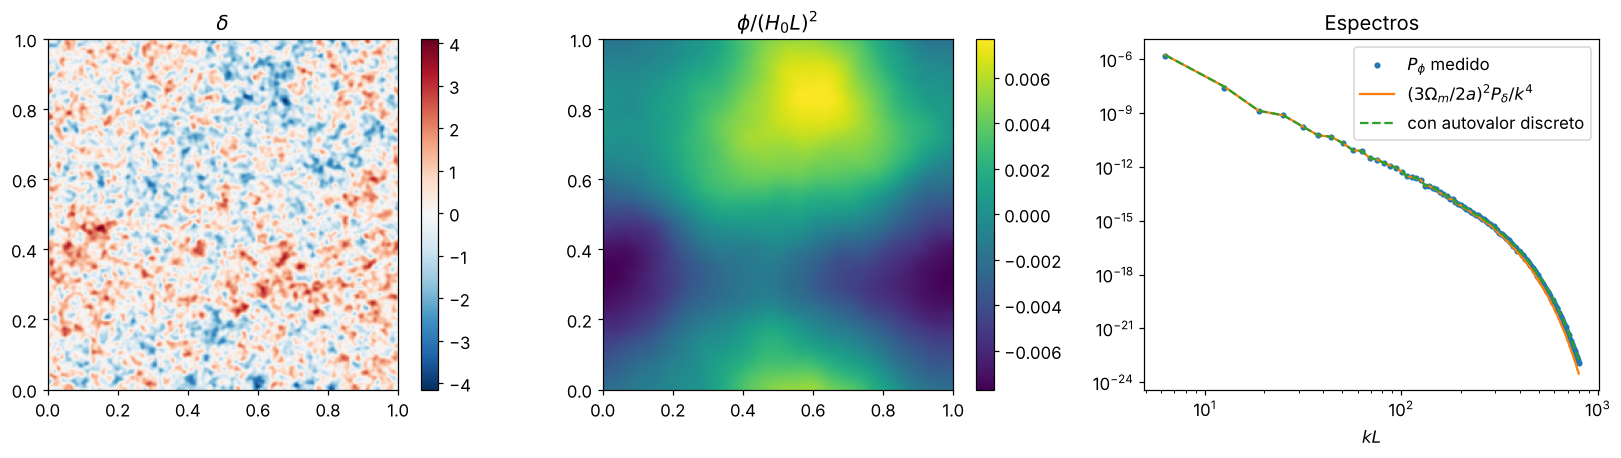

In [6]:
N, Om, a = 256, 0.3, 1.0
generar_delta(N)
print(correr(N, metodo=2, tol=1e-10, modo=1, Om=Om, a=a))

with open("salida_cpu.bin", "rb") as f:
    nx, ny, nc, nb = (int(v) for v in np.fromfile(f, dtype=np.int32, count=4))  # int(): evita overflow de int32
    phi, delta = np.fromfile(f, dtype=np.float64).reshape(nc, ny, nx)

h = 1.0/N; pref = 1.5*Om/a
k1 = 2*np.pi*np.fft.fftfreq(N, d=h)
kx, ky = np.meshgrid(k1, k1, indexing="xy")
lam = -4/h**2*(np.sin(kx*h/2)**2 + np.sin(ky*h/2)**2); lam[0, 0] = 1.0
phik = pref*np.fft.fft2(delta - delta.mean())/lam; phik[0, 0] = 0.0
phi_fft = np.fft.ifft2(phik).real
print(f"Diferencia relativa máxima iterativo vs FFT: {np.abs(phi-phi_fft).max()/np.abs(phi_fft).max():.2e}")

kmod = np.sqrt(kx**2 + ky**2)
bordes = (np.arange(0.5, N//2, 1.0))*2*np.pi
idx = np.digitize(kmod.ravel(), bordes)
def espectro(campo):
    p = (np.abs(np.fft.fft2(campo))**2/float(N)**4).ravel()
    return np.array([p[idx == i].mean() for i in range(1, len(bordes))])
kc = 0.5*(bordes[1:] + bordes[:-1])
Pd, Pp = espectro(delta), espectro(phi)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
im = ax[0].imshow(delta, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r"); ax[0].set_title(r"$\delta$"); plt.colorbar(im, ax=ax[0])
im = ax[1].imshow(phi, origin="lower", extent=[0, 1, 0, 1]); ax[1].set_title(r"$\phi/(H_0L)^2$"); plt.colorbar(im, ax=ax[1])
ax[2].loglog(kc, Pp, ".", label=r"$P_\phi$ medido")
ax[2].loglog(kc, pref**2*Pd/kc**4, "-", label=r"$(3\Omega_m/2a)^2P_\delta/k^4$")
ax[2].loglog(kc, pref**2*Pd/(4*N**2*np.sin(kc/(2*N))**2)**2, "--", label="con autovalor discreto")
ax[2].set_xlabel(r"$kL$"); ax[2].legend(); ax[2].set_title("Espectros")
plt.tight_layout(); plt.show()

En $k$ alto el espectro medido se separa de $k^{-4}$ porque el laplaciano discreto tiene autovalor $\tfrac{4}{h^2}\sin^2(kh/2) < k^2$; con el autovalor discreto (línea discontinua) el acuerdo es completo.

## 6. Para qué sirve: simulación particle-mesh 2D

Una simulación cosmológica de N-cuerpos es una solución Monte Carlo de Vlasov–Poisson. En cada paso:

1. **Depósito CIC**: cada partícula reparte su masa entre las 4 celdas vecinas → $\delta(\mathbf x)$.
2. **Poisson comóvil** → $\phi$ (aquí con FFT para que sea rápido; es el paso que el proyecto acelera en GPU).
3. **Fuerza** $\mathbf g = -\nabla\phi$ con diferencias centradas, interpolada a las partículas con CIC.
4. **Leapfrog KDK** usando $a$ como tiempo. Con el momento $\mathbf p = a^2\dot{\mathbf x}$ y $dt = da/(aH)$:

$$
\frac{d\mathbf p}{da} = -\frac{\nabla\phi}{aH},\qquad \frac{d\mathbf x}{da} = \frac{\mathbf p}{a^3H},\qquad H = H_0\,a^{-3/2}\ \ (\text{EdS}).
$$

**Condiciones iniciales de Zel'dovich**: $\mathbf x = \mathbf q + D(a)\,\boldsymbol\psi(\mathbf q)$ con $\delta = -\nabla\cdot\boldsymbol\psi$, es decir $\hat{\boldsymbol\psi}_{\mathbf k} = i\mathbf k\,\hat\delta_{\mathbf k}/k^2$, y $D = a$ en EdS.

Es un juguete: dinámica 2D con los coeficientes de 3D. Pero el algoritmo es el de GADGET o RAMSES.

In [7]:
Ng = Np = 256
rng = np.random.default_rng(3)
k1 = 2*np.pi*np.fft.fftfreq(Ng, 1/Ng)
KX, KY = np.meshgrid(k1, k1, indexing="ij"); K2 = KX**2 + KY**2; K2[0, 0] = 1
P = np.sqrt(K2)**-1.0*np.exp(-K2/(2*np.pi*40)**2); P[0, 0] = 0
dk = np.fft.fft2(rng.normal(size=(Ng, Ng)))*np.sqrt(P)
dk *= 0.9/np.fft.ifft2(dk).real.std()          # sigma lineal = 0.9 en a = 1
sigma_lin = 0.9

psx = np.fft.ifft2(1j*KX*dk/K2).real; psy = np.fft.ifft2(1j*KY*dk/K2).real
q = (np.arange(Np) + 0.5)/Np; QX, QY = np.meshgrid(q, q, indexing="ij")
H = lambda a: a**-1.5
a = 0.02
x = (QX + a*psx) % 1; y = (QY + a*psy) % 1
px = a**2*(a*H(a))*psx; py = a**2*(a*H(a))*psy

def pesos(x, y):
    fx = x*Ng - 0.5; fy = y*Ng - 0.5
    i = np.floor(fx).astype(int); j = np.floor(fy).astype(int)
    return i, j, fx - i, fy - j

def cic(x, y):
    g = np.zeros((Ng, Ng)); i, j, tx, ty = pesos(x, y)
    for di, wx in ((0, 1 - tx), (1, tx)):
        for dj, wy in ((0, 1 - ty), (1, ty)):
            np.add.at(g, ((i + di) % Ng, (j + dj) % Ng), wx*wy)
    return g/g.mean() - 1

def interp(F, x, y):
    i, j, tx, ty = pesos(x, y); out = 0
    for di, wx in ((0, 1 - tx), (1, tx)):
        for dj, wy in ((0, 1 - ty), (1, ty)):
            out = out + F[(i + di) % Ng, (j + dj) % Ng]*wx*wy
    return out

lam = -(4*Ng**2)*(np.sin(KX/(2*Ng))**2 + np.sin(KY/(2*Ng))**2); lam[0, 0] = 1
def fuerza(x, y, a):
    d = cic(x, y)
    phik = 1.5/a*np.fft.fft2(d)/lam; phik[0, 0] = 0     # <- Poisson comóvil (Om = 1)
    phi = np.fft.ifft2(phik).real
    gx = -(np.roll(phi, -1, 0) - np.roll(phi, 1, 0))*Ng/2
    gy = -(np.roll(phi, -1, 1) - np.roll(phi, 1, 1))*Ng/2
    return interp(gx, x, y), interp(gy, x, y), d, phi

hist_a, hist_sd, hist_sp, snaps = [], [], [], {}
da = 0.004; t0 = time.time()
gx, gy, d, phi = fuerza(x, y, a)
while a < 1.0 - 1e-9:
    hist_a.append(a); hist_sd.append(d.std()); hist_sp.append(phi.std())
    for ao in (0.1, 0.3):
        if abs(a - ao) < da/2: snaps[ao] = (x.copy(), y.copy(), phi.copy())
    px += gx/(a*H(a))*da/2; py += gy/(a*H(a))*da/2                  # kick
    am = a + da/2
    x = (x + px/(am**3*H(am))*da) % 1; y = (y + py/(am**3*H(am))*da) % 1   # drift
    a += da
    gx, gy, d, phi = fuerza(x, y, a)
    px += gx/(a*H(a))*da/2; py += gy/(a*H(a))*da/2                  # kick
hist_a.append(a); hist_sd.append(d.std()); hist_sp.append(phi.std())
snaps[1.0] = (x, y, phi)
print(f"{len(hist_a)} pasos, {time.time() - t0:.1f} s")

246 pasos, 4.7 s


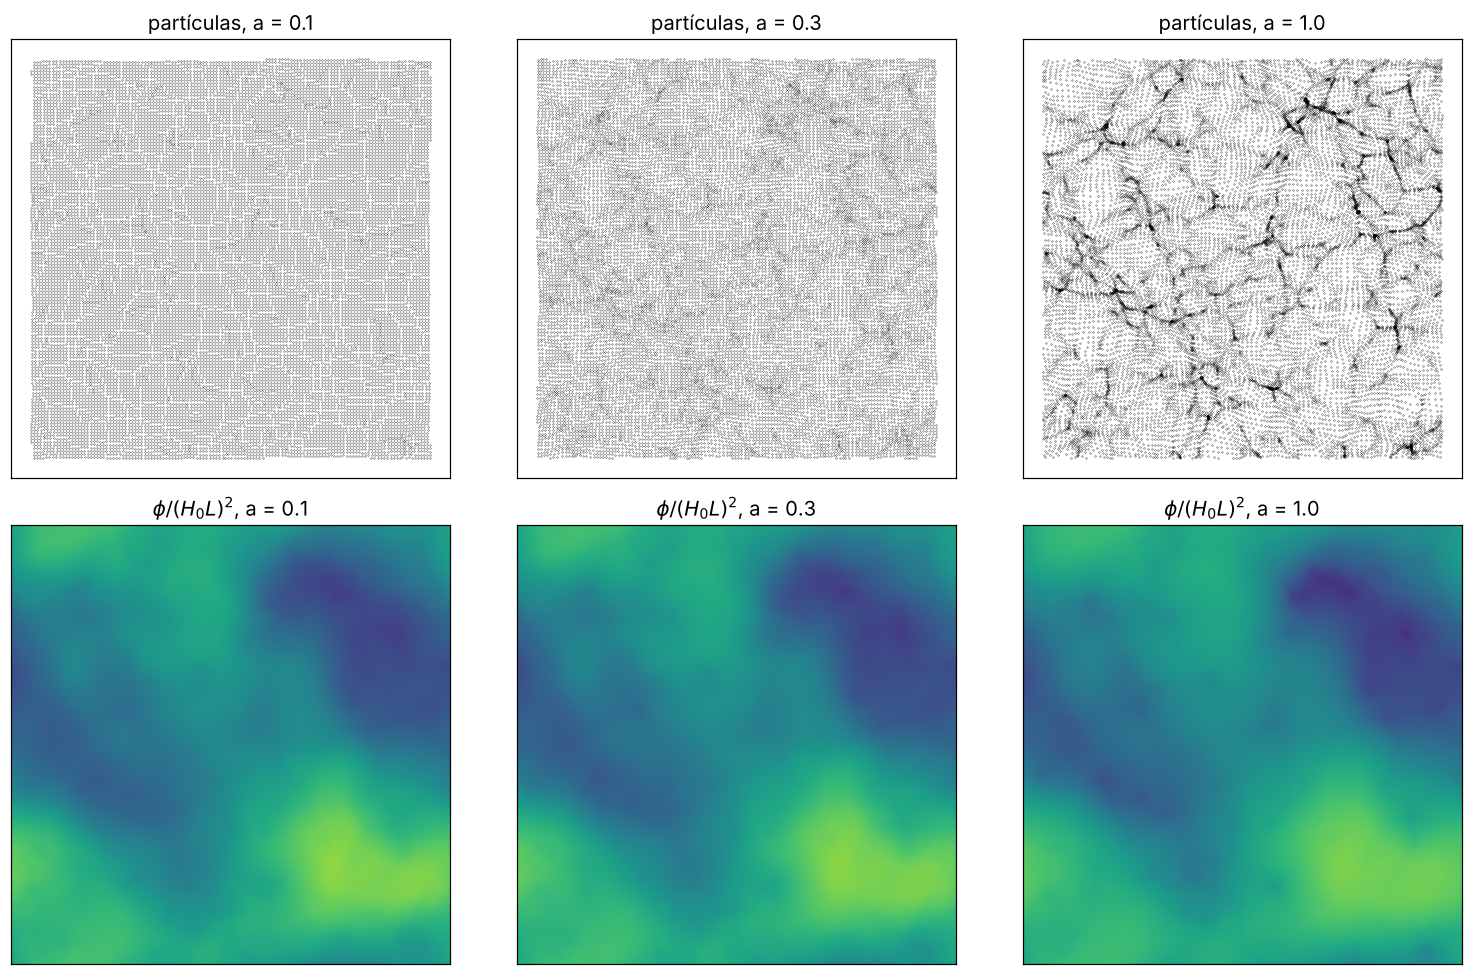

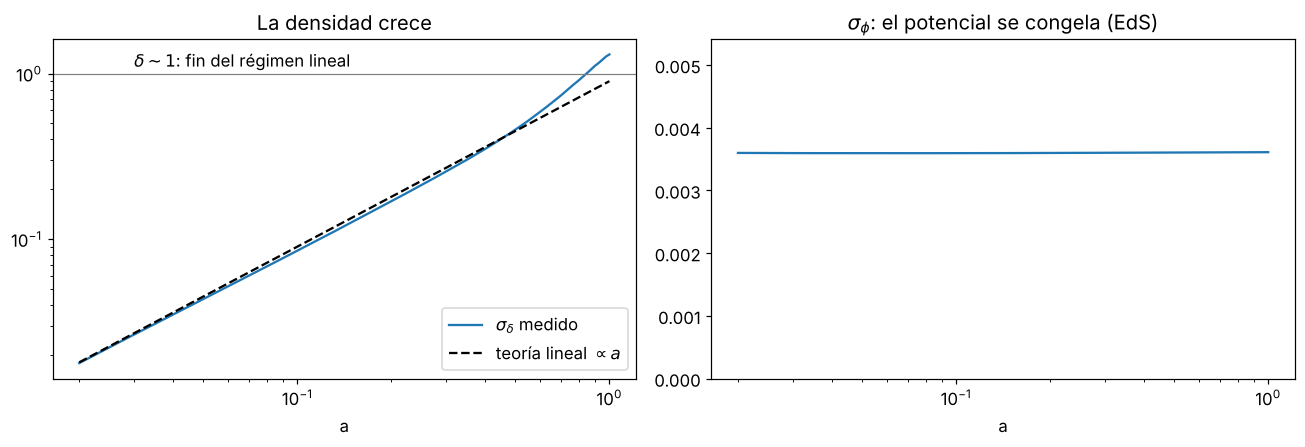

In [8]:
fig, ax = plt.subplots(2, 3, figsize=(14, 9))
for c, ao in enumerate((0.1, 0.3, 1.0)):
    X, Y, ph = snaps[ao]
    ax[0, c].scatter(X[::2, ::2], Y[::2, ::2], s=0.05, c="k"); ax[0, c].set_title(f"partículas, a = {ao}")
    ax[1, c].imshow(ph.T, origin="lower", extent=[0, 1, 0, 1], vmin=-0.012, vmax=0.012)
    ax[1, c].set_title(rf"$\phi/(H_0L)^2$, a = {ao}")
    for A in ax[:, c]: A.set_aspect("equal"); A.set_xticks([]); A.set_yticks([])
plt.tight_layout(); plt.show()

A = np.array(hist_a)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].loglog(A, hist_sd, label=r"$\sigma_\delta$ medido")
ax[0].loglog(A, sigma_lin*A, "k--", label=r"teoría lineal $\propto a$")
ax[0].axhline(1, color="gray", lw=0.8); ax[0].text(0.03, 1.1, r"$\delta\sim1$: fin del régimen lineal")
ax[0].set_xlabel("a"); ax[0].legend(); ax[0].set_title("La densidad crece")
ax[1].semilogx(A, hist_sp); ax[1].set_ylim(0, 1.5*max(hist_sp))
ax[1].set_xlabel("a"); ax[1].set_title(r"$\sigma_\phi$: el potencial se congela (EdS)")
plt.tight_layout(); plt.show()

**Lectura de los gráficos.** Mientras $\sigma_\delta \ll 1$ el crecimiento sigue la teoría lineal $\delta\propto a$; cerca de $\sigma_\delta\sim1$ aparecen los filamentos (cruce de corrientes) y la teoría lineal deja de valer: ahí solo sirve simular. El potencial, dominado por escalas grandes que siguen lineales, queda prácticamente constante, como predice $\phi\propto a^2\bar\rho\,\delta$ en Einstein–de Sitter.

## 7. Siguiente paso: CUDA

En Colab: *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)*, y luego `!nvcc --version`.
La versión 1 porta los kernels `jacobi` y `media_iteracion_rb` (un thread por punto, índices periódicos), la reducción del residuo y `restar_promedio`, manteniendo `u`, `f` y `delta` en la GPU.

### Referencias
- P. J. E. Peebles, *The Large-Scale Structure of the Universe* (1980).
- E. Bertschinger, *ARA&A* 36, 599 (1998).
- S. Dodelson & F. Schmidt, *Modern Cosmology*, 2.ª ed. (2020).
- R. W. Hockney & J. W. Eastwood, *Computer Simulation Using Particles* (1988).
- C. Barrera-Hinojosa & B. Li, GRAMSES Part I, arXiv:1905.08890.
- Ya. B. Zel'dovich, *A&A* 5, 84 (1970).
- W. H. Press et al., *Numerical Recipes*, 3.ª ed. (2007), §20.5.